<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-064-one-qubit.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 064. One qubit, measurements and gates as rotations

A qubit is a quantum system whose states form a two-dimensional complex vector space, spanned by two orthogonal states. The spin-1/2, the intrinsic angular momentum of an electron whose component along any axis takes only two values, gives the geometric picture used throughout, and a register of $N$ qubits consists of $N$ such systems that can be driven and measured one by one and made to interact. The physical platforms that realise qubits, with their two levels, drives, couplings and readout, are the subject of Part II of the lecture and of Lab 067.

In every quantum experiment, and on every quantum computer, we *prepare* a state, let it *evolve* under a Hamiltonian switched on for a chosen time, and *measure* it. Each run returns one bit, 0 or 1. Quantum mechanics predicts the probabilities of the two bits, and we compare them with records of many repeated runs. For one qubit we compute the outcome probabilities, the expectation values of the Pauli observables and the Bloch vector of the state. We then study finite records of shots and the action of every standard gate as a rotation of the Bloch sphere.

The core route runs through Sections 0 to 11. Section 0 compares a qubit with a classical and a probabilistic bit. Sections 1 to 5 introduce the state vector, the Born rule, the phases, the Pauli observables and the Bloch sphere. Sections 6 to 9 show that evolution and every gate are rotations of the Bloch sphere and end with an interference experiment. Measurements in other bases follow in Section 10 and finite records of shots in Section 11. The Euler decomposition of Section 12 lies beyond the core route.

The prerequisites are linear algebra with complex numbers (vectors, matrices, eigenvalues and the conjugate transpose), basic probability and reading Python with NumPy. No course in quantum mechanics is assumed, and every physics word is explained where it first appears. The same objects carry different names in physics, mathematics and computer science.

| physics | mathematics | computer science |
|---|---|---|
| state $\lvert\psi\rangle$ of a qubit | unit vector in $\mathbb C^2$ | memory of one qubit, two complex numbers |
| state of $N$ qubits | unit vector in $\mathbb C^{2^N}=(\mathbb C^2)^{\otimes N}$ | array of $2^N$ complex numbers |
| observable | Hermitian matrix | quantity whose average we estimate |
| time evolution, gate | unitary matrix | reversible operation, an instruction of a program |
| measurement outcome | eigenvalue, chosen with Born probabilities | random bit, a sample |
| ket $\lvert\psi\rangle$, bra $\langle\psi\rvert$ | column vector, its conjugate transpose | `psi`, `psi.conj()` |

Four rules, the postulates of quantum mechanics for qubits, define everything that follows.
1. The state of $N$ qubits is a unit vector in $\mathbb C^{2^N}$, defined up to a global phase.
2. Between measurements the state is multiplied by a unitary matrix $\hat U$, the evolution generated by a Hamiltonian, $\hat U=e^{-i\hat{\mathcal H}t}$ for a constant Hamiltonian (Section 6).
3. A measurement in the computational basis returns the bit string $b$ with probability $|\langle b|\psi\rangle|^2$, the Born rule (Section 2), and leaves the state in $|b\rangle$.
4. The state space of several qubits is the tensor product of their state spaces.

No model is trained, and every number comes from exact state vectors or from simulated measurement records with fixed random seeds.

In [1]:
# JAX in double precision, plotting style and output folders
import os, json, time
os.environ["JAX_PLATFORMS"] = "cpu"                # small dense matrices: the CPU suffices, no GPU is used
import numpy as np
import jax
import jax.numpy as jnp
from jax.scipy.linalg import expm
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)        # float64 / complex128 everywhere
CDTYPE = jnp.complex128
TOL = 1e-12                                       # tolerance of the exact checks
os.makedirs("figures", exist_ok=True)
os.makedirs("classroom_results", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "figure.dpi": 110})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
FIGSIZE = (4.5, 3.0)
started = time.perf_counter()
NUMBERS = {}                                      # numbers exported as LaTeX macros

def save(fig, name, tight=True):
    # tight=False keeps the figure at its exact size, for figures drawn at their final print size
    bbox = "tight" if tight else None
    fig.savefig(f"figures/{name}.pdf", bbox_inches=bbox)
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches=bbox)

print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 0. Bits, probabilistic bits and qubits

A classical bit takes one of two values, 0 or 1. A probabilistic bit, for example a coin before we look at it, is described by the vector of its two probabilities,
$$\mathbf p=(p_0,p_1),\qquad p_0,p_1\ge0,\qquad p_0+p_1=1, \tag{1}$$
a stochastic vector. Reading it out returns 0 or 1 with these probabilities, and its operations are stochastic matrices, whose columns are probability vectors. A qubit is described by a vector of two complex amplitudes,
$$(a,b),\qquad a,b\in\mathbb C,\qquad |a|^2+|b|^2=1, \tag{2}$$
and reading it out returns 0 or 1 with the probabilities $|a|^2$ and $|b|^2$, the Born rule. Its operations are unitary matrices. Both models return random bits. They differ in the amplitudes, which can be negative or complex and can cancel each other, as probabilities never do. The code samples the three objects and applies the Hadamard matrix twice, which returns the qubit to its initial amplitudes.

In [2]:
rng_bits = np.random.default_rng(640)                          # own generator for this illustration
bit = 1                                                        # a classical bit
p_vec = np.array([0.75, 0.25])                                 # a probabilistic bit: stochastic vector
amp = np.array([np.sqrt(3) / 2, np.exp(1j * np.pi / 4) / 2])   # a qubit: unit complex vector
assert abs(p_vec.sum() - 1) < 1e-12 and abs(np.vdot(amp, amp) - 1) < 1e-12
print("classical bit, read 10 times       :", [bit] * 10)
print("probabilistic bit, 10 samples      :", rng_bits.choice(2, size=10, p=p_vec).tolist())
print("qubit, 10 samples from |a|^2, |b|^2:", rng_bits.choice(2, size=10, p=np.abs(amp) ** 2).tolist())
# operations: a stochastic matrix keeps probability vectors, a unitary keeps unit vectors
flip_noisy = np.array([[0.9, 0.2], [0.1, 0.8]])                # columns are probability vectors
hadamard = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
print("stochastic matrix on (1, 0), twice :", flip_noisy @ flip_noisy @ np.array([1.0, 0.0]))
print("Hadamard on |0>, twice             :", np.round(hadamard @ hadamard @ np.array([1.0, 0.0]), 12), " (amplitudes cancel)")


classical bit, read 10 times       : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
probabilistic bit, 10 samples      : [0, 0, 1, 0, 0, 0, 0, 0, 1, 0]
qubit, 10 samples from |a|^2, |b|^2: [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
stochastic matrix on (1, 0), twice : [0.83 0.17]
Hadamard on |0>, twice             : [ 1. -0.]  (amplitudes cancel)


## 1. The state vector of one qubit

We choose two orthogonal basis states, in which the spin points up or down along the $z$ axis, and call them $|0\rangle$ and $|1\rangle$,
$$|0\rangle=\begin{pmatrix}1\\0\end{pmatrix},\qquad |1\rangle=\begin{pmatrix}0\\1\end{pmatrix}. \tag{3}$$
This basis is the *computational basis*. When the qubit is encoded in two energy levels, we label the ground state $|0\rangle\equiv|g\rangle$ and the excited state $|1\rangle\equiv|e\rangle$, and for a spin-1/2 $|0\rangle=|{\uparrow}\rangle$ and $|1\rangle=|{\downarrow}\rangle$. A measurement in this basis then reads out the energy level.

The symbol $|\cdot\rangle$, a *ket*, denotes a column vector. Its conjugate transpose is a row vector, the *bra* $\langle\cdot|=(|\cdot\rangle)^\dagger$, where the dagger means complex conjugation followed by transposition. A bra times a ket is the *inner product* $\langle\phi|\psi\rangle=\sum_k\phi_k^*\psi_k$, a complex number. Two states are orthogonal when their inner product vanishes, as $\langle0|1\rangle=0$, and a state is normalised when $\langle\psi|\psi\rangle=1$. A general state is a superposition
$$|\psi\rangle=a\,|0\rangle+b\,|1\rangle=\begin{pmatrix}a\\b\end{pmatrix},\qquad |a|^2+|b|^2=1, \tag{4}$$
with the two complex *amplitudes* $a$ and $b$. On a computer the state of one qubit is an array of two complex numbers. Our example state is
$$|\psi_{\rm ex}\rangle=\frac{\sqrt3}{2}\,|0\rangle+\frac{e^{i\pi/4}}{2}\,|1\rangle , \tag{5}$$
normalised because $3/4+1/4=1$.

In [3]:
ket0 = jnp.array([1, 0], dtype=CDTYPE)
ket1 = jnp.array([0, 1], dtype=CDTYPE)

def normalise(v):
    return v / jnp.linalg.norm(v)

psi_ex = jnp.sqrt(3) / 2 * ket0 + jnp.exp(1j * jnp.pi / 4) / 2 * ket1
print("amplitudes a, b =", np.round(np.asarray(psi_ex), 4))
print("norm squared   =", float(jnp.vdot(psi_ex, psi_ex).real))
assert abs(jnp.vdot(psi_ex, psi_ex) - 1) < TOL
assert abs(jnp.vdot(ket0, ket1)) < TOL           # the basis states are orthogonal

amplitudes a, b = [0.866 +0.j     0.3536+0.3536j]
norm squared   = 0.9999999999999999


## 2. Measurement in the computational basis and the Born rule

A measurement in the computational basis returns a single bit, and the *Born rule* gives the probabilities
$$p(0)=|\langle0|\psi\rangle|^2=|a|^2,\qquad p(1)=|\langle1|\psi\rangle|^2=|b|^2 . \tag{6}$$
The normalisation of the state, equation (4), becomes $p(0)+p(1)=1$. After the measurement the qubit is left in the basis state that was found, so a second measurement in the same basis repeats the result. Each run gives one bit, and we learn the probabilities from many runs on identically prepared qubits.

For the example state (5) the Born rule gives $p(0)=|\sqrt3/2|^2=3/4$ and $p(1)=|e^{i\pi/4}/2|^2=1/4$. The phase $e^{i\pi/4}$ drops out of this measurement.

In [4]:
def born_probabilities(psi):
    # Born rule in the computational basis: p(k) = |<k|psi>|^2
    return jnp.abs(psi) ** 2

p_ex = born_probabilities(psi_ex)
print("p(0), p(1) for psi_ex:", np.round(np.asarray(p_ex), 6))
assert jnp.allclose(p_ex, jnp.array([0.75, 0.25]), atol=TOL)
assert abs(p_ex.sum() - 1) < TOL
NUMBERS["PzeroEx"] = float(p_ex[0])

p(0), p(1) for psi_ex: [0.75 0.25]


## 3. Global and relative phase

Multiplying the whole state by a phase factor, $|\psi\rangle\to e^{i\alpha}|\psi\rangle$, changes no prediction. Every Born probability contains the amplitudes in pairs $a^*a$, $b^*b$ or $a^*b$, in which $e^{-i\alpha}e^{i\alpha}=1$ cancels. This *global phase* is unobservable, so we may always choose $a$ real and non-negative.

The phase between the amplitudes, the *relative phase*, is observable. The states
$$|{+}\rangle=\frac{|0\rangle+|1\rangle}{\sqrt2},\qquad |{-}\rangle=\frac{|0\rangle-|1\rangle}{\sqrt2} \tag{7}$$
differ only by the relative phase $e^{i\pi}=-1$ of the second amplitude. They share $|a|^2$ and $|b|^2$, yet they are orthogonal, $\langle{+}|{-}\rangle=0$, so some measurement distinguishes them with certainty. The code checks that a global phase leaves the squared moduli unchanged and that the overlap of $|{+}\rangle$ and $|{-}\rangle$ vanishes.

In [5]:
plus  = normalise(ket0 + ket1)
minus = normalise(ket0 - ket1)
psi_phase = jnp.exp(1j * 0.73) * psi_ex                     # a global phase
print("|a|^2,|b|^2 of psi_ex           :", np.round(np.abs(np.asarray(psi_ex))**2, 4))
print("|a|^2,|b|^2 with a global phase :", np.round(np.abs(np.asarray(psi_phase))**2, 4))
print("|a|^2,|b|^2 of |+> and |->      :", np.round(np.abs(np.asarray(plus))**2, 4), np.round(np.abs(np.asarray(minus))**2, 4))
print("overlap <+|->                   :", complex(jnp.vdot(plus, minus)))
assert jnp.allclose(jnp.abs(psi_phase)**2, jnp.abs(psi_ex)**2, atol=TOL)
assert abs(jnp.vdot(plus, minus)) < TOL

|a|^2,|b|^2 of psi_ex           : [0.75 0.25]
|a|^2,|b|^2 with a global phase : [0.75 0.25]
|a|^2,|b|^2 of |+> and |->      : [0.5 0.5] [0.5 0.5]
overlap <+|->                   : (-2.2371143170757382e-17+0j)


## 4. Observables and the Pauli matrices

A measurement that records $+1$ for the outcome 0 and $-1$ for the outcome 1 measures the spin along $z$. Its average over many runs is
$$\langle \hat Z\rangle=(+1)\,p(0)+(-1)\,p(1)=p(0)-p(1). \tag{8}$$
A ket times a bra, in the opposite order, is the *outer product* $|a\rangle\langle b|$, a $2\times2$ matrix with the entries $a_jb_k^*$. The matrices $|0\rangle\langle0|=\mathrm{diag}(1,0)$ and $|1\rangle\langle1|=\mathrm{diag}(0,1)$ are *projectors*, since applying either twice equals applying it once, and $|0\rangle\langle0|\psi\rangle=a|0\rangle$ keeps only the $|0\rangle$ component. A matrix equal to its own conjugate transpose, $\hat O^\dagger=\hat O$, is *Hermitian*, and its eigenvalues are real.

Quantum mechanics represents an observable by a Hermitian matrix whose eigenvectors are the possible post-measurement states and whose eigenvalues are the recorded values. For the spin along $z$ this is the Pauli matrix $\hat Z$, and with the spin components along $x$ and $y$ we have
$$\hat X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad \hat Y=\begin{pmatrix}0&-i\\ i&0\end{pmatrix},\qquad \hat Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}, \tag{9}$$
also written $\hat\sigma_x\equiv \hat X$, $\hat\sigma_y\equiv \hat Y$, $\hat\sigma_z\equiv \hat Z$ and $\hat{\boldsymbol\sigma}=(\hat\sigma_x,\hat\sigma_y,\hat\sigma_z)$. Each has the eigenvalues $\pm1$ and squares to the identity, and $\hat Z=|0\rangle\langle0|-|1\rangle\langle1|$. Two different Pauli matrices anticommute, so their product changes sign when the order is reversed,
$$\hat X\hat Y=-\hat Y\hat X=i\hat Z,\qquad \hat Y\hat Z=-\hat Z\hat Y=i\hat X,\qquad \hat Z\hat X=-\hat X\hat Z=i\hat Y . \tag{10}$$
The eigenvectors of $\hat Z$ are $|0\rangle$ and $|1\rangle$, those of $\hat X$ are $|{\pm}\rangle$, and those of $\hat Y$ are $|{\pm i}\rangle=(|0\rangle\pm i|1\rangle)/\sqrt2$. The average of an observable $\hat O$ in the state $|\psi\rangle$ is the *expectation value*
$$\langle \hat O\rangle=\langle\psi|\hat O|\psi\rangle=\sum_{k}\lambda_k\,p(\lambda_k), \tag{11}$$
the sum of the eigenvalues $\lambda_k$ weighted with their Born probabilities. For $\hat Z$ it recovers equation (8), and for the example state we expect $\langle \hat Z\rangle=3/4-1/4=1/2$.

In [6]:
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
PAULIS = {"X": X, "Y": Y, "Z": Z}

def expectation(O, psi):
    return jnp.vdot(psi, O @ psi).real

for name, P in PAULIS.items():
    w, v = jnp.linalg.eigh(P)
    assert jnp.allclose(P, P.conj().T) and jnp.allclose(P @ P, I2)       # Hermitian, squares to 1
    print(f"{name}: eigenvalues {np.round(np.asarray(w).real, 3)}, eigenvector of +1 = {np.round(np.asarray(v[:, 1]), 3)}")

# different Pauli matrices anticommute: XY = -YX = iZ and cyclically
for A, B, C in ((X, Y, Z), (Y, Z, X), (Z, X, Y)):
    assert jnp.allclose(A @ B, -B @ A, atol=TOL) and jnp.allclose(A @ B, 1j * C, atol=TOL)
print("XY = -YX = iZ, YZ = -ZY = iX, ZX = -XZ = iY checked")

ez = expectation(Z, psi_ex)
print("<Z> =", float(ez), "  p(0) - p(1) =", float(p_ex[0] - p_ex[1]))
assert abs(ez - (p_ex[0] - p_ex[1])) < TOL and abs(ez - 0.5) < TOL

X: eigenvalues [-1.  1.], eigenvector of +1 = [0.707+0.j 0.707+0.j]
Y: eigenvalues [-1.  1.], eigenvector of +1 = [-0.707+0.j     0.   -0.707j]
Z: eigenvalues [-1.  1.], eigenvector of +1 = [1.+0.j 0.+0.j]
XY = -YX = iZ, YZ = -ZY = iX, ZX = -XZ = iY checked
<Z> = 0.4999999999999999   p(0) - p(1) = 0.4999999999999999


### 4.1 The Pauli algebra and the ladder operators

The products of the Pauli matrices close among themselves. With $\hat\sigma_1\equiv \hat X$, $\hat\sigma_2\equiv \hat Y$ and $\hat\sigma_3\equiv \hat Z$,
$$\hat\sigma_a\hat\sigma_b=\delta_{ab}\,\hat I+i\sum_c\varepsilon_{abc}\,\hat\sigma_c , \tag{12}$$
where $\delta_{ab}$ equals one for $a=b$ and zero otherwise. The Levi-Civita symbol $\varepsilon_{abc}$ is $+1$ for a cyclic order of $(1,2,3)$, $-1$ for the other orders and zero when two indices coincide. Adding and subtracting equation (12) with $a$ and $b$ exchanged gives the commutator and the anticommutator,
$$[\hat\sigma_a,\hat\sigma_b]=2i\sum_c\varepsilon_{abc}\hat\sigma_c,\qquad \{\hat\sigma_a,\hat\sigma_b\}=2\delta_{ab}\hat I . \tag{13}$$
Every Pauli matrix has trace zero, so the trace of equation (12) gives $\mathrm{Tr}(\hat\sigma_a\hat\sigma_b)=2\delta_{ab}$. The matrices $\hat I,\hat X,\hat Y,\hat Z$ are therefore orthogonal under the inner product $\mathrm{Tr}(\hat A^\dagger \hat B)$, and every complex $2\times2$ matrix is a combination $\hat A=c_0\hat I+c_x\hat X+c_y\hat Y+c_z\hat Z$ with $c_0=\mathrm{Tr}\hat A/2$ and $c_\alpha=\mathrm{Tr}(\hat\sigma_\alpha \hat A)/2$.

The ladder operators change one basis state into the other. For a spin-1/2 with $|0\rangle=|{\uparrow}\rangle$ and $|1\rangle=|{\downarrow}\rangle$ we define
$$\hat\sigma^\pm=\hat\sigma_x\pm i\hat\sigma_y,\qquad \hat\sigma^+=\begin{pmatrix}0&2\\0&0\end{pmatrix}=2|0\rangle\langle1|,\qquad \hat\sigma^-=\begin{pmatrix}0&0\\2&0\end{pmatrix}=2|1\rangle\langle0| . \tag{14}$$
The raising operator $\hat\sigma^+$ turns $|1\rangle$ into $2|0\rangle$ and annihilates $|0\rangle$, and the lowering operator $\hat\sigma^-$ acts in the opposite direction. They are adjoint to each other, $(\hat\sigma^+)^\dagger=\hat\sigma^-$, and they satisfy $\hat X=(\hat\sigma^++\hat\sigma^-)/2$, $\hat Y=(\hat\sigma^+-\hat\sigma^-)/(2i)$, $(\hat\sigma^\pm)^2=0$, $\hat\sigma^+\hat\sigma^-=2(\hat I+\hat Z)$ and $[\hat\sigma^+,\hat\sigma^-]=4\hat Z$. The spin ladder operators $\hat S^\pm=\hat\sigma^\pm/2$ have unit matrix elements.

The ladder operators are named after the spin, so $\hat\sigma^+$ raises the spin from $|{\downarrow}\rangle$ to $|{\uparrow}\rangle$. With the ground state $|0\rangle=|g\rangle=|{\uparrow}\rangle$, raising the spin lowers the energy. The decay of the excited state is therefore $|g\rangle\langle e|=|0\rangle\langle1|=\hat S^+$, and the excitation is $|e\rangle\langle g|=|1\rangle\langle0|=\hat S^-$. The code checks every relation of this section.

In [7]:
sig = [X, Y, Z]
def levi_civita(a, b, c):
    return int(np.sign((b - a) * (c - a) * (c - b)))         # +1 cyclic, -1 anticyclic, 0 repeated
for a in range(3):
    for b in range(3):
        eps_sum = sum(levi_civita(a, b, c) * sig[c] for c in range(3))
        assert jnp.allclose(sig[a] @ sig[b], (a == b) * I2 + 1j * eps_sum, atol=TOL)              # product rule
        assert jnp.allclose(sig[a] @ sig[b] - sig[b] @ sig[a], 2j * eps_sum, atol=TOL)            # commutator
        assert jnp.allclose(sig[a] @ sig[b] + sig[b] @ sig[a], 2 * (a == b) * I2, atol=TOL)       # anticommutator
        assert abs(jnp.trace(sig[a] @ sig[b]) - 2 * (a == b)) < TOL
# decomposition of a random complex 2x2 matrix in the basis I, X, Y, Z
kA, kB = jax.random.split(jax.random.PRNGKey(6404))           # own key; the shot records use key 64
A_rand = jax.random.normal(kA, (2, 2)) + 1j * jax.random.normal(kB, (2, 2))
c = [jnp.trace(A_rand) / 2] + [jnp.trace(P @ A_rand) / 2 for P in sig]
assert jnp.allclose(c[0] * I2 + c[1] * X + c[2] * Y + c[3] * Z, A_rand, atol=TOL)
# ladder operators sigma^pm = sigma_x +- i sigma_y and S^pm = sigma^pm / 2
sp, sm = X + 1j * Y, X - 1j * Y
assert jnp.allclose(sp, 2 * jnp.outer(ket0, ket1.conj()), atol=TOL) and jnp.allclose(sm, 2 * jnp.outer(ket1, ket0.conj()), atol=TOL)
assert jnp.allclose(sp @ ket1, 2 * ket0, atol=TOL) and jnp.allclose(sp @ ket0, 0 * ket0, atol=TOL)
assert jnp.allclose(sm @ ket0, 2 * ket1, atol=TOL) and jnp.allclose(sm @ ket1, 0 * ket1, atol=TOL)
assert jnp.allclose((sp + sm) / 2, X, atol=TOL) and jnp.allclose((sp - sm) / 2j, Y, atol=TOL)
assert jnp.allclose(sp @ sp, 0 * I2, atol=TOL) and jnp.allclose(sm @ sm, 0 * I2, atol=TOL)
assert jnp.allclose(sp @ sm, 2 * (I2 + Z), atol=TOL) and jnp.allclose(sp @ sm - sm @ sp, 4 * Z, atol=TOL)
# decay |g><e| = |0><1| = S^+ = sigma^+/2 (raises the spin, lowers the energy), excitation |e><g| = |1><0| = S^- = sigma^-/2
assert jnp.allclose(jnp.outer(ket0, ket1.conj()), sp / 2, atol=TOL) and jnp.allclose(jnp.outer(ket1, ket0.conj()), sm / 2, atol=TOL)
print("decay |g><e| = |0><1| = sigma^+/2, excitation |e><g| = |1><0| = sigma^-/2")
print("sigma_a sigma_b = delta_ab I + i eps_abc sigma_c, commutators, anticommutators, Tr(sigma_a sigma_b) = 2 delta_ab checked")
print("random 2x2 matrix rebuilt from c0 I + c.sigma")
print("sigma^+ =\n", np.asarray(sp.real).astype(int), "\nsigma^- =\n", np.asarray(sm.real).astype(int))


decay |g><e| = |0><1| = sigma^+/2, excitation |e><g| = |1><0| = sigma^-/2
sigma_a sigma_b = delta_ab I + i eps_abc sigma_c, commutators, anticommutators, Tr(sigma_a sigma_b) = 2 delta_ab checked
random 2x2 matrix rebuilt from c0 I + c.sigma
sigma^+ =
 [[0 2]
 [0 0]] 
sigma^- =
 [[0 0]
 [2 0]]


## 5. The Bloch sphere

Up to the global phase, every normalised state of one qubit is fixed by two angles,
$$|\psi\rangle=\cos\frac{\vartheta}{2}\,|0\rangle+e^{i\varphi}\sin\frac{\vartheta}{2}\,|1\rangle,\qquad 0\le\vartheta\le\pi,\quad 0\le\varphi<2\pi . \tag{15}$$
They are the polar and azimuthal angles of a point on a unit sphere, the *Bloch sphere*. The north pole is $|0\rangle$, the south pole $|1\rangle$, and the equator holds the equal superpositions such as $|{\pm}\rangle$ and $|{\pm i}\rangle$. The Cartesian coordinates of the point are the three expectation values,
$$\mathbf r=(\langle \hat X\rangle,\langle \hat Y\rangle,\langle \hat Z\rangle)=(\sin\vartheta\cos\varphi,\ \sin\vartheta\sin\varphi,\ \cos\vartheta), \tag{16}$$
which form the *Bloch vector*. A pure state has $|\mathbf r|=1$. The relative phase is the azimuth $\varphi$, so it drops out of $\langle \hat Z\rangle$ and appears in $\langle \hat X\rangle$ and $\langle \hat Y\rangle$.

For the example state, $\cos(\vartheta/2)=\sqrt3/2$ gives $\vartheta=\pi/3$, and $\varphi=\pi/4$, so the Bloch vector is $\mathbf r=(\tfrac{\sqrt3}{2}\cos\tfrac\pi4,\ \tfrac{\sqrt3}{2}\sin\tfrac\pi4,\ \tfrac12)\approx(0.612,\,0.612,\,0.5)$.

In [8]:
def bloch_vector(psi):
    return jnp.array([expectation(P, psi) for P in (X, Y, Z)])

def state_from_angles(theta, phi):
    return jnp.array([jnp.cos(theta / 2), jnp.exp(1j * phi) * jnp.sin(theta / 2)], dtype=CDTYPE)

r_ex = bloch_vector(psi_ex)
r_formula = jnp.array([jnp.sin(jnp.pi/3) * jnp.cos(jnp.pi/4), jnp.sin(jnp.pi/3) * jnp.sin(jnp.pi/4), jnp.cos(jnp.pi/3)])
print("Bloch vector of psi_ex:", np.round(np.asarray(r_ex), 4), " length", float(jnp.linalg.norm(r_ex)))
assert jnp.allclose(r_ex, r_formula, atol=TOL)
assert jnp.allclose(state_from_angles(jnp.pi/3, jnp.pi/4), psi_ex, atol=TOL)
for name, s in {"|0>": ket0, "|1>": ket1, "|+>": plus, "|->": minus, "|+i>": normalise(ket0 + 1j*ket1)}.items():
    print(f"{name:5s} r =", np.round(np.asarray(bloch_vector(s)), 3))
NUMBERS.update(BlochExX=float(r_ex[0]), BlochExY=float(r_ex[1]), BlochExZ=float(r_ex[2]))

Bloch vector of psi_ex: [0.6124 0.6124 0.5   ]  length 0.9999999999999999
|0>   r = [0. 0. 1.]
|1>   r = [ 0.  0. -1.]
|+>   r = [ 1.  0. -0.]
|->   r = [-1.  0. -0.]
|+i>  r = [ 0.  1. -0.]


## 6. Evolution under a Hamiltonian

The Hamiltonian $\hat{\mathcal H}$ is the Hermitian matrix of the energy of a system. Its eigenvalues are the allowed energies, the energy levels, and its eigenvectors are the states of definite energy. It also generates the change of the state in time. A closed system, which exchanges nothing with its surroundings, obeys the Schrödinger equation $i\hbar\,\frac{d}{dt}|\psi\rangle=\hat{\mathcal H}|\psi\rangle$, where $\hbar$ is the reduced Planck constant. We use units with $\hbar=1$, in which energies are angular frequencies. For a Hamiltonian that does not depend on time the solution is
$$|\psi(t)\rangle=\hat U(t)\,|\psi(0)\rangle,\qquad \hat U(t)=e^{-i\hat{\mathcal H}t}, \tag{17}$$
with the matrix exponential defined by the power series $e^{\hat A}=\sum_k \hat A^k/k!$. Differentiating the power series gives $\frac{d}{dt}\hat U=-i\hat{\mathcal H}\,\hat U(t)$, so equation (17) solves the Schrödinger equation with the initial value $\hat U(0)=\hat I$. A Hermitian $\hat{\mathcal H}$ makes $\hat U^\dagger(t)=e^{+i\hat{\mathcal H}t}$ and $\hat U^\dagger \hat U=\hat I$, and the *evolution operator* therefore preserves normalisation. All powers of $\hat{\mathcal H}$ commute, which gives the composition rule $\hat U(t_1+t_2)=\hat U(t_1)\,\hat U(t_2)$. In the eigenbasis of the Hamiltonian, with eigenvalues $E_k$ and orthonormal eigenvectors $|E_k\rangle$, every power acts as $\hat{\mathcal H}^m|E_k\rangle=E_k^m|E_k\rangle$, so
$$\hat U(t)=\sum_k e^{-iE_kt}\,|E_k\rangle\langle E_k| . \tag{18}$$
An energy eigenstate acquires only a phase, so its measurement probabilities stay constant, and a superposition of eigenstates changes through the relative phases $e^{-i(E_k-E_l)t}$.

A Hamiltonian proportional to $\hat Z$, $\hat{\mathcal H}=\frac\omega2\hat Z$ with an angular frequency $\omega$, has the energies $+\omega/2$ on $|0\rangle$ and $-\omega/2$ on $|1\rangle$. Its evolution operator is diagonal,
$$\hat U(t)=\begin{pmatrix}e^{-i\omega t/2}&0\\0&e^{i\omega t/2}\end{pmatrix}=e^{-i\omega t\hat Z/2}\equiv\hat R_z(\omega t), \tag{19}$$
and up to a global phase it multiplies the amplitude of $|1\rangle$ by $e^{i\omega t}$. In the Bloch form (15) the azimuth grows as $\varphi\to\varphi+\omega t$ while $\vartheta$ stays fixed, so the Bloch vector turns about the $z$ axis with the angular frequency $\omega$. This motion is called *precession*, and $\hat R_z(\theta)=e^{-i\theta\hat Z/2}$ is the *rotation gate* about $z$ by the angle $\theta$.

A term $\hat{\mathcal H}=\frac\Omega2\hat X$, a drive of strength $\Omega$ switched on for a time $t$, couples $|0\rangle$ and $|1\rangle$ and generates
$$\hat U(t)=e^{-i\theta\hat X/2}\equiv\hat R_x(\theta),\qquad \theta=\Omega t , \tag{20}$$
the rotation gate about $x$ by the angle $\theta$. Starting from $|0\rangle$, the probability of the bit 1 oscillates in time as
$$p(1)=|\langle1|\hat R_x(\Omega t)|0\rangle|^2=\sin^2\frac{\Omega t}{2} . \tag{21}$$
The angle $\theta=\pi$ takes $|0\rangle$ to $|1\rangle$ and gives $\hat X$ up to the global phase $-i$, and the angle $\theta=\pi/2$ makes the equal superposition $(|0\rangle-i|1\rangle)/\sqrt2$. The term $\frac\Omega2\hat Y$ generates $\hat R_y(\theta)=e^{-i\theta\hat Y/2}$ in the same way. Each gate is thus a Hamiltonian switched on for a chosen time, with the rotation angle given by the strength of the term times the duration.

We evolve the example state under the Hamiltonian of equation (19) and check that $\langle \hat Z\rangle$ stays constant while the azimuth grows as $\varphi_0+\omega t$. For the drive of equation (20) the code checks equation (21) and the two angles $\pi$ and $\pi/2$. For the Hamiltonian $\frac\Omega2\hat X+\frac\omega2\hat Z$, which contains both terms, it compares `expm` with the spectral form (18), integrates the Schrödinger equation with small fourth-order Runge–Kutta steps and verifies the composition rule.

In [9]:
def evolve(Hm, t, psi):
    return expm(-1j * Hm * t) @ psi

omega = 2.0
ts = jnp.linspace(0, jnp.pi, 7)
for t in ts:
    r = bloch_vector(evolve(omega / 2 * Z, t, psi_ex))
    phi = float(jnp.arctan2(r[1], r[0]))
    expected = (np.pi / 4 + omega * float(t) + np.pi) % (2 * np.pi) - np.pi
    assert abs(r[2] - 0.5) < 1e-10 and abs(np.angle(np.exp(1j * (phi - expected)))) < 1e-10
print("precession with H = (omega/2) Z, omega = 2: <Z> constant at 0.5, azimuth = pi/4 + omega t  (checked at", len(ts), "times)")
Omega, t = 1.3, 0.9
assert jnp.allclose(expm(-1j * Omega / 2 * X * t), expm(-1j * (Omega * t) * X / 2), atol=TOL)
print("drive: exp(-i (Omega/2) X t) = R_x(Omega t) checked")
for t in np.linspace(0, 4 * np.pi / Omega, 9):
    assert abs(float(born_probabilities(evolve(Omega / 2 * X, t, ket0))[1]) - np.sin(Omega * t / 2) ** 2) < 1e-12
assert jnp.allclose(expm(-1j * np.pi / 2 * X), -1j * X, atol=1e-12)                          # theta = pi: X up to -i
assert jnp.allclose(expm(-1j * np.pi / 4 * X) @ ket0, (ket0 - 1j * ket1) / jnp.sqrt(2), atol=1e-12)   # theta = pi/2
print("p(1) = sin^2(Omega t / 2) from |0>; theta = pi gives -i X; theta = pi/2 gives (|0> - i|1>)/sqrt(2)")

precession with H = (omega/2) Z, omega = 2: <Z> constant at 0.5, azimuth = pi/4 + omega t  (checked at 7 times)
drive: exp(-i (Omega/2) X t) = R_x(Omega t) checked
p(1) = sin^2(Omega t / 2) from |0>; theta = pi gives -i X; theta = pi/2 gives (|0> - i|1>)/sqrt(2)


In [10]:
# U = exp(-i H t) as the solution of i d|psi>/dt = H |psi>, for H = (Omega/2) X + (omega/2) Z
Om, om = 1.3, 2.0
Hm = Om / 2 * X + om / 2 * Z
E, V = jnp.linalg.eigh(Hm)
def U_spectral(t):
    return V @ jnp.diag(jnp.exp(-1j * E * t)) @ V.conj().T          # sum_k exp(-i E_k t) |E_k><E_k|
t_end = 2.7
assert jnp.allclose(expm(-1j * Hm * t_end), U_spectral(t_end), atol=1e-12)          # (i) expm = spectral form

def rk4(psi0, t_end, steps):
    # fourth-order Runge-Kutta for d psi/dt = -i H psi
    Hn = np.asarray(Hm)                                   # NumPy inside the loop: many small steps run faster than in JAX
    f = lambda p: -1j * (Hn @ p)
    dt, p = t_end / steps, np.asarray(psi0)
    for _ in range(steps):
        k1 = f(p); k2 = f(p + dt / 2 * k1); k3 = f(p + dt / 2 * k2); k4 = f(p + dt * k3)
        p = p + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return p
psi_ode = rk4(psi_ex, t_end, 400)
err = float(np.linalg.norm(psi_ode - np.asarray(expm(-1j * Hm * t_end) @ psi_ex)))
assert err < 1e-9                                                                   # (ii) ODE solution = U(t) psi(0)
t1, t2 = 0.8, 1.9
assert jnp.allclose(expm(-1j * Hm * (t1 + t2)), expm(-1j * Hm * t1) @ expm(-1j * Hm * t2), atol=1e-12)   # (iii)
assert jnp.allclose(U_spectral(t_end).conj().T @ U_spectral(t_end), I2, atol=1e-12)                       # unitary
print(f"expm = spectral form; RK4 with 400 steps differs from expm by {err:.1e}; U(t1+t2) = U(t1)U(t2); U is unitary")


expm = spectral form; RK4 with 400 steps differs from expm by 1.1e-10; U(t1+t2) = U(t1)U(t2); U is unitary


## 7. Gates as rotations

For a matrix $\hat P$ with $\hat P^2=\hat I$, the even powers in the exponential series equal $\hat I$ and the odd powers equal $\hat P$. Splitting the series gives
$$e^{-ia\hat P}=\sum_m\frac{(-ia)^{2m}}{(2m)!}\,\hat I+\sum_m\frac{(-ia)^{2m+1}}{(2m+1)!}\,\hat P=\cos a\,\hat I-i\sin a\,\hat P , \tag{22}$$
the matrix version of Euler's formula. Every Pauli matrix squares to $\hat I$, and so does $\mathbf n\cdot\hat{\boldsymbol\sigma}=n_x\hat X+n_y\hat Y+n_z\hat Z$ for a unit vector $\mathbf n$, because different Pauli matrices anticommute, equation (10). The rotation about the axis $\mathbf n$ by the angle $\theta$ is therefore
$$\hat R_{\mathbf n}(\theta)=e^{-i\theta\,\mathbf n\cdot\hat{\boldsymbol\sigma}/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\mathbf n\cdot\hat{\boldsymbol\sigma} . \tag{23}$$
It turns the Bloch vector by $\theta$ about $\mathbf n$, counterclockwise when seen from the tip of $\mathbf n$. For $\hat R_z(\theta)$ this is the precession of Section 6, and the code checks the general statement on a random state and a random axis. The angle $\theta/2$ in the exponent becomes the angle $\theta$ on the sphere because the Bloch vector is quadratic in the amplitudes. Equation (22) also gives two-qubit rotations, since $\hat X\otimes \hat X$ squares to the identity as well.

Every single-qubit gate is such a rotation, up to a global phase that no measurement detects. The gate $\hat X$ is the *bit flip*, $\hat X|0\rangle=|1\rangle$ and $\hat X|1\rangle=|0\rangle$. The gate $\hat Z$ is the *phase flip*, which leaves $|0\rangle$ unchanged and multiplies $|1\rangle$ by $-1$. The *phase gates* $\hat S$ and $\hat T$ multiply $|1\rangle$ by $i$ and $e^{i\pi/4}$, and the *Hadamard gate* $\hat H=(\hat X+\hat Z)/\sqrt2$ turns $|0\rangle$ into $|{+}\rangle$ and $|1\rangle$ into $|{-}\rangle$. Each gate $\hat G=e^{i\eta}\hat R_{\mathbf n}(\theta)$ is the evolution under a generator $\hat{\mathcal H}_G$ switched on for the time $t=1$,
$$\hat G=e^{-i\hat{\mathcal H}_G},\qquad \hat{\mathcal H}_G=\frac\theta2\,\mathbf n\cdot\hat{\boldsymbol\sigma}-\eta \hat I , \tag{24}$$
where the term with $\hat I$ produces the global phase $e^{i\eta}$. For the five gates of the table $\eta=\theta/2$, so their generators are $\hat{\mathcal H}_G=\frac\theta2(\mathbf n\cdot\hat{\boldsymbol\sigma}-\hat I)$.

| gate | matrix | rotation | axis $\mathbf n$ | angle $\theta$ | global phase | generator $\hat{\mathcal H}_G$ |
|---|---|---|---|---|---|---|
| $\hat X$ | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | $i\,\hat R_x(\pi)$ | $x$ | $\pi$ | $i$ | $\frac\pi2(\hat X-\hat I)$ |
| $\hat Z$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | $i\,\hat R_z(\pi)$ | $z$ | $\pi$ | $i$ | $\frac\pi2(\hat Z-\hat I)$ |
| $\hat H$ | $\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | $i\,\hat R_{\mathbf n}(\pi)$ | $(x+z)/\sqrt2$ | $\pi$ | $i$ | $\frac\pi2(\hat H-\hat I)$ |
| $\hat S$ | $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ | $e^{i\pi/4}\hat R_z(\pi/2)$ | $z$ | $\pi/2$ | $e^{i\pi/4}$ | $\frac\pi4(\hat Z-\hat I)$ |
| $\hat T$ | $\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}$ | $e^{i\pi/8}\hat R_z(\pi/4)$ | $z$ | $\pi/4$ | $e^{i\pi/8}$ | $\frac\pi8(\hat Z-\hat I)$ |

The Hadamard gate is a half turn about the axis halfway between $x$ and $z$, which exchanges the $z$ and $x$ axes of the Bloch sphere. The code checks equation (22) against the matrix exponential and every row of the table, including the generator. It also recovers the axis, angle and global phase of a gate from its matrix. For a gate without rotation, such as $\hat I$ or $\hat H^2$, the angle is zero and every axis is valid, and the function returns the $z$ axis.

In [11]:
H = (X + Z) / jnp.sqrt(2)                                  # Hadamard
S = jnp.diag(jnp.array([1, 1j], dtype=CDTYPE))             # phase gate S
T = jnp.diag(jnp.array([1, jnp.exp(1j * jnp.pi / 4)], dtype=CDTYPE))   # phase gate T

def rotation(n, theta):
    n = jnp.asarray(n, dtype=jnp.float64) / jnp.linalg.norm(jnp.asarray(n, dtype=jnp.float64))
    ns = n[0] * X + n[1] * Y + n[2] * Z
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * ns

def Rx(t): return rotation((1, 0, 0), t)
def Ry(t): return rotation((0, 1, 0), t)
def Rz(t): return rotation((0, 0, 1), t)

# the closed form agrees with the matrix exponential
for n in [(1, 0, 0), (0, 1, 0), (0, 0, 1), (1, 2, -0.5)]:
    nn = np.array(n) / np.linalg.norm(n)
    for theta in (0.3, 1.7, np.pi):
        U_exp = expm(-1j * theta / 2 * (nn[0] * X + nn[1] * Y + nn[2] * Z))
        assert jnp.allclose(rotation(n, theta), U_exp, atol=TOL)

def axis_angle_phase(U):
    # U = phase * R_n(theta); remove the phase with det(R_n) = 1, then read cos and sin parts
    phase = jnp.sqrt(jnp.linalg.det(U))
    V = U / phase
    c = (jnp.trace(V) / 2).real
    if c < 0:                                   # choose the representative with theta in [0, pi]
        V, phase, c = -V, -phase, -c
    theta = 2 * jnp.arccos(jnp.clip(c, -1, 1))
    s = jnp.sin(theta / 2)
    if s < 1e-9:                                # no rotation: every axis is valid, return z by convention
        return jnp.array([0.0, 0.0, 1.0]), 0.0 * theta, phase
    n = jnp.array([(1j * jnp.trace(V @ P) / (2 * s)).real for P in (X, Y, Z)])
    return n, theta, phase

for G0 in (I2, H @ H, jnp.exp(0.7j) * I2):    # zero rotation, with and without a global phase
    n0, th0, ph0 = axis_angle_phase(G0)
    assert float(th0) == 0.0 and jnp.allclose(n0, jnp.array([0.0, 0.0, 1.0])) and jnp.allclose(ph0 * I2, G0, atol=TOL)

n_H = jnp.array([1, 0, 1]) / jnp.sqrt(2)
table_gates = {"X": (X, 1j * Rx(jnp.pi)), "Z": (Z, 1j * Rz(jnp.pi)), "H": (H, 1j * rotation(n_H, jnp.pi)),
               "S": (S, jnp.exp(1j * jnp.pi / 4) * Rz(jnp.pi / 2)), "T": (T, jnp.exp(1j * jnp.pi / 8) * Rz(jnp.pi / 4))}
for name, (G, as_rotation) in table_gates.items():
    assert jnp.allclose(G, as_rotation, atol=TOL)
    n, theta, phase = axis_angle_phase(G)
    print(f"{name}: axis {np.round(np.asarray(n), 3)}, angle {float(theta) / np.pi:.3f} pi, global phase {complex(np.round(complex(phase), 4))}")
generators = {"X": (jnp.pi, X), "Z": (jnp.pi, Z), "H": (jnp.pi, H), "S": (jnp.pi / 2, Z), "T": (jnp.pi / 4, Z)}
for name, (theta, P) in generators.items():
    assert jnp.allclose(expm(-1j * theta / 2 * (P - I2)), table_gates[name][0], atol=TOL)   # G = exp(-i H_G)
print("every gate of the table equals exp(-i H_G) with H_G = (theta/2)(n.sigma - I)")
# R_n(theta) turns the Bloch vector by theta about n (Rodrigues' rotation formula), on a random state and axis
key_rot = jax.random.PRNGKey(6401)                     # own key; the shot records below use key 64
ka, kb, kc = jax.random.split(key_rot, 3)
n_rand = np.array(jax.random.normal(ka, (3,))); n_rand /= np.linalg.norm(n_rand)
v = jax.random.normal(kb, (2,)) + 1j * jax.random.normal(kc, (2,)); psi_rand = v / jnp.linalg.norm(v)
for theta in (0.4, 1.9, 3.0):
    r = np.asarray(jnp.array([expectation(P, psi_rand) for P in (X, Y, Z)]))
    r_rot = np.asarray(jnp.array([expectation(P, rotation(n_rand, theta) @ psi_rand) for P in (X, Y, Z)]))
    rodrigues = r * np.cos(theta) + np.cross(n_rand, r) * np.sin(theta) + n_rand * (n_rand @ r) * (1 - np.cos(theta))
    assert np.allclose(r_rot, rodrigues, atol=1e-10)
print("R_n(theta) turns the Bloch vector by theta about n, counterclockwise seen from the tip of n")
assert jnp.allclose(rotation((0.3, -0.2, 0.9), 2 * jnp.pi), -I2, atol=TOL)
print("R_n(2 pi) = -I: a full turn returns every Bloch vector but multiplies the state by -1")

X: axis [1. 0. 0.], angle 1.000 pi, global phase 1j
Z: axis [0. 0. 1.], angle 1.000 pi, global phase 1j
H: axis [0.707 0.    0.707], angle 1.000 pi, global phase 1j
S: axis [0. 0. 1.], angle 0.500 pi, global phase (0.7071+0.7071j)
T: axis [0. 0. 1.], angle 0.250 pi, global phase (0.9239+0.3827j)
every gate of the table equals exp(-i H_G) with H_G = (theta/2)(n.sigma - I)
R_n(theta) turns the Bloch vector by theta about n, counterclockwise seen from the tip of n
R_n(2 pi) = -I: a full turn returns every Bloch vector but multiplies the state by -1


### 7.1 Each gate as a matrix and an action

The table above gives each single-qubit gate as a matrix in the computational basis. The table below adds its action on the basis states $|0\rangle,|1\rangle$ and on $|{\pm}\rangle$, which the code prints and checks together with the rotation form of each gate.

| gate | action on basis states |
|---|---|
| $\hat X$ | $|0\rangle\leftrightarrow|1\rangle$, $|{\pm}\rangle\to\pm|{\pm}\rangle$ |
| $\hat Y$ | $|0\rangle\to i|1\rangle$, $|1\rangle\to-i|0\rangle$ |
| $\hat Z$ | $|0\rangle\to|0\rangle$, $|1\rangle\to-|1\rangle$, $|{\pm}\rangle\leftrightarrow|{\mp}\rangle$ |
| $\hat S$, $\hat T$ | phase $i$ or $e^{i\pi/4}$ on $|1\rangle$ |
| $\hat H$ | $|0\rangle\leftrightarrow|{+}\rangle$, $|1\rangle\leftrightarrow|{-}\rangle$ |
| $\hat R_x(\theta)$, $\hat R_y(\theta)$ | rotation by $\theta$ about $x$ or $y$ |
| $\hat R_z(\theta)$ | phase $e^{\mp i\theta/2}$ on $|0\rangle$, $|1\rangle$ |

The fixed gates are particular angles of the three rotations, $\hat X$ and $\hat Y$ at $\theta=\pi$ about $x$ and $y$, and $\hat Z$, $\hat S$, $\hat T$ at $\theta=\pi$, $\pi/2$, $\pi/4$ about $z$. Each angle is the strength of the generating term times the time for which it acts, equation (20).

In [12]:
# each gate: matrix, action on |0>, |1>, |+>, |->, and its rotation form up to a global phase
def equal_up_to_phase(A, B):
    k = int(np.argmax(np.abs(np.asarray(B)).ravel()))
    ph = np.asarray(A).ravel()[k] / np.asarray(B).ravel()[k]
    return abs(abs(ph) - 1) < 1e-9 and np.allclose(np.asarray(A), ph * np.asarray(B), atol=1e-9)

named = {"|0>": ket0, "|1>": ket1, "|+>": plus, "|->": minus}
def name_of(v):
    for nm, w in named.items():
        ov = complex(jnp.vdot(w, v))
        if abs(abs(ov) - 1) < 1e-9:
            ph = complex(np.round(ov, 3))   # phase in front of the named state
            return (f"{ph.real:+g}" if abs(ph.imag) < 1e-9 else (f"{ph.imag:+g}i" if abs(ph.real) < 1e-9 else f"({ph.real:g}{ph.imag:+g}i)")) + nm
    return "superposition"

as_rotation = {
    "X": (X, Rx(jnp.pi)),
    "Y": (Y, Ry(jnp.pi)),
    "Z": (Z, Rz(jnp.pi)),
    "S": (S, Rz(jnp.pi / 2)),
    "T": (T, Rz(jnp.pi / 4)),
    "H": (H, rotation(n_H, jnp.pi)),
}
for name, (G, R_G) in as_rotation.items():
    assert equal_up_to_phase(G, R_G)
    action = ", ".join(f"{nm} -> {name_of(G @ v)}" for nm, v in named.items())
    print(f"{name}: matrix {np.round(np.asarray(G), 3).tolist()}\n   action: {action}")
print("every gate equals its rotation up to a global phase")

X: matrix [[0j, (1+0j)], [(1+0j), 0j]]
   action: |0> -> +1|1>, |1> -> +1|0>, |+> -> +1|+>, |-> -> -1|->
Y: matrix [[0j, (-0-1j)], [1j, 0j]]
   action: |0> -> +1i|1>, |1> -> -1i|0>, |+> -> -1i|->, |-> -> +1i|+>
Z: matrix [[(1+0j), 0j], [0j, (-1+0j)]]
   action: |0> -> +1|0>, |1> -> -1|1>, |+> -> +1|->, |-> -> +1|+>
S: matrix [[(1+0j), 0j], [0j, 1j]]
   action: |0> -> +1|0>, |1> -> +1i|1>, |+> -> superposition, |-> -> superposition
T: matrix [[(1+0j), 0j], [0j, (0.707+0.707j)]]
   action: |0> -> +1|0>, |1> -> (0.707+0.707i)|1>, |+> -> superposition, |-> -> superposition
H: matrix [[(0.707+0j), (0.707+0j)], [(0.707+0j), (-0.707+0j)]]
   action: |0> -> +1|+>, |1> -> +1|->, |+> -> +1|0>, |-> -> +1|1>
every gate equals its rotation up to a global phase


## 8. Gates seen on the Bloch sphere

To follow the evolution that implements a gate $\hat G=e^{i\eta}\hat R_{\mathbf n}(\theta)$, we switch on the Hamiltonian $\hat{\mathcal H}=\frac{\theta}{2}\,\mathbf n\cdot\hat{\boldsymbol\sigma}$ for the times $0\le t\le1$, so that $\hat U(t)=\hat R_{\mathbf n}(\theta t)$ ends at the gate. The initial state has $\vartheta=2\pi/3$ and $\varphi=\pi/3$, away from every rotation axis. We plot the path of its Bloch vector for $\hat X$ and $\hat H$ on one sphere and for $\hat Z$, $\hat S$ and $\hat T$, which share the $z$ axis, on a second sphere. Each path is an arc of a circle around the axis of the gate and covers the angle of the gate.

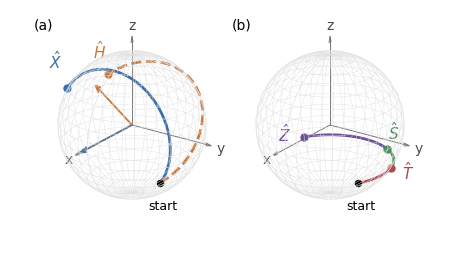

In [13]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)

start = state_from_angles(2 * jnp.pi / 3, jnp.pi / 3)
ts = jnp.linspace(0, 1, 61)
paths = {}
for name in ["X", "Z", "H", "S", "T"]:
    n, theta, phase = axis_angle_phase(table_gates[name][0])
    path = jnp.stack([bloch_vector(rotation(n, theta * t) @ start) for t in ts])
    final = bloch_vector(table_gates[name][0] @ start)
    assert jnp.allclose(path[-1], final, atol=1e-10)           # the path ends where the gate sends the state
    assert jnp.allclose(path @ n, path[0] @ n, atol=1e-10)     # the component along the axis is conserved
    paths[name] = (np.asarray(path), np.asarray(n))
for name, frac in (("T", 0.25), ("S", 0.5)):                   # T and S end a quarter and half way along the Z arc
    z_arc = np.asarray([bloch_vector(Rz(jnp.pi * frac) @ start)])[0]
    assert np.allclose(paths[name][0][-1], z_arc, atol=1e-10)

fig = plt.figure(figsize=(3.96, 2.15))                          # final size: 0.6 of a 6.6 in text width
u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
colors = {"X": "#3b6ea8", "H": "#c8783a", "Z": "#6d4f9c", "S": "#4a8a5a", "T": "#b04a4a"}
label_off = {"X": (0.0, -0.05, 0.32), "H": (0.15, 0.0, 0.3), "Z": (0.0, -0.3, 0.0), "S": (0.0, 0.0, 0.3), "T": (0.15, 0.25, 0.15)}
z_path = paths["Z"][0]
segments = {"T": (0, 15), "S": (15, 30), "Z": (30, 60)}       # pieces of the Z arc: start to T, T to S, S to Z
r0 = np.asarray(bloch_vector(start))
for k, (group, panel) in enumerate([(("X", "H"), "(a)"), (("Z", "S", "T"), "(b)")]):
    ax = fig.add_axes([-0.05 + 0.5 * k, -0.13, 0.6, 1.2], projection="3d")
    ax.patch.set_alpha(0)
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="0.88", lw=0.3)
    for lab, d in {"x": (1, 0, 0), "y": (0, 1, 0), "z": (0, 0, 1)}.items():
        ax.quiver(0, 0, 0, *(1.25 * np.array(d)), color="0.45", lw=0.7, arrow_length_ratio=0.07)
        ax.text(*(1.4 * np.array(d)), lab, fontsize=10, color="0.3", ha="center", va="center")
    if k == 0:
        for name in group:
            path, n = paths[name]
            ax.plot(*path.T, color=colors[name], lw=2.0, ls="-" if name == "X" else "--")
            ax.quiver(0, 0, 0, *(1.15 * n), color=colors[name], lw=1.3, arrow_length_ratio=0.12)   # rotation axis
    else:
        for name, (a, b) in segments.items():
            ax.plot(*z_path[a:b + 1].T, color=colors[name], lw=2.0)
    for name in group:
        e = paths[name][0][-1]
        ax.plot(*e, "o", color=colors[name], ms=5, zorder=5)
        ax.text(*(e * 1.12 + np.array(label_off[name])), rf"$\hat {name}$", color=colors[name], fontsize=11, ha="center", va="center")
    ax.plot(*r0, "ko", ms=4.5)
    ax.text(*(r0 * 1.1 + np.array([0, 0, -0.24])), "start", fontsize=9, ha="center", va="center")
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.view_init(elev=22, azim=35)
    ax.set_xlim(-0.95, 0.95); ax.set_ylim(-0.95, 0.95); ax.set_zlim(-0.95, 0.95)
    fig.text(0.01 + 0.5 * k, 0.93, panel, fontsize=10)
save(fig, "fig_lab064_gate_rotations", tight=False); plt.show()

Panel (a) shows the paths of $\hat X$ and $\hat H$, each with its rotation axis drawn as an arrow of the same colour. Both gates turn the state half a circle, about the $x$ axis and about the diagonal axis between $x$ and $z$. Panel (b) shows the gates that rotate about $z$. The state moves along one circle at constant height, and the labelled dots mark where each gate stops. The gate $\hat T$ stops after an eighth of a turn, $\hat S$ after a quarter and $\hat Z$ after a half, so the path of $\hat T$ is the first half of the path of $\hat S$, which is the first half of the path of $\hat Z$. Along every arc the component of the Bloch vector along the axis stays fixed, as the code checks.

## 9. A one-qubit circuit and interference

A *circuit* is a sequence of gates applied to a prepared state, followed by a measurement. Gates act on the state from the left, so the gate applied first stands rightmost in the product. The circuit with $\hat H$ first and $\hat S$ second is the matrix $\hat S\hat H$, which differs from $\hat H\hat S$. Starting from $|0\rangle$, the state $\hat S\hat H|0\rangle=\hat S|{+}\rangle=|{+i}\rangle$ points along $y$, whereas $\hat H\hat S|0\rangle=\hat H|0\rangle=|{+}\rangle$ points along $x$, because $\hat S$ leaves $|0\rangle$ unchanged. The circuit $\hat H$, then $\hat Z$, then $\hat H$ is the matrix $\hat H\hat Z\hat H$. The Hadamard gate exchanges the $x$ and $z$ axes, so a half turn about $z$ framed by two Hadamard gates is a half turn about $x$,
$$\hat H\hat Z\hat H=\hat X . \tag{25}$$
The circuit flips $|0\rangle$ to $|1\rangle$ with certainty. The first Hadamard gate prepares $|{+}\rangle$, the $\hat Z$ gate changes the relative phase to give $|{-}\rangle$, and the second Hadamard gate turns this phase into a different bit.

Replacing $\hat Z$ by $\hat R_z(\phi)$ gives a *Ramsey interference* experiment. The amplitude of $|1\rangle$ after $\hat H\,\hat R_z(\phi)\,\hat H|0\rangle$ is $\tfrac12(e^{-i\phi/2}-e^{i\phi/2})=-i\sin(\phi/2)$, so
$$p(1)=\sin^2\frac{\phi}{2}. \tag{26}$$
Without the second Hadamard gate, $p(1)=1/2$ for every $\phi$, and the phase stays hidden.

first H then S: [ 0.  1. -0.]   first S then H: [ 1.  0. -0.]
p(1) after H Z H |0> = 0.9999999999999996


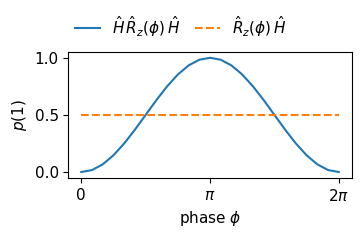

In [14]:
r_SH, r_HS = bloch_vector(S @ H @ ket0), bloch_vector(H @ S @ ket0)
print("first H then S:", np.round(np.asarray(r_SH), 3), "  first S then H:", np.round(np.asarray(r_HS), 3))
assert jnp.allclose(r_SH, jnp.array([0, 1, 0]), atol=TOL) and jnp.allclose(r_HS, jnp.array([1, 0, 0]), atol=TOL)
assert jnp.allclose(H @ Z @ H, X, atol=TOL)
print("p(1) after H Z H |0> =", float(born_probabilities(H @ Z @ H @ ket0)[1]))

phis = np.linspace(0, 2 * np.pi, 25)
p1_with, p1_without = [], []
for phi in phis:
    p_w = float(born_probabilities(H @ Rz(phi) @ H @ ket0)[1])
    p_wo = float(born_probabilities(Rz(phi) @ H @ ket0)[1])
    assert abs(p_w - np.sin(phi / 2) ** 2) < 1e-12 and abs(p_wo - 0.5) < 1e-12
    p1_with.append(p_w); p1_without.append(p_wo)

def plot_ramsey(size, name):
    # drawn at its final printed size with 11 pt text, so the figure is placed without scaling
    rc = {"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11}
    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=size, layout="constrained")
        ax.plot(phis, p1_with, "-", label=r"$\hat H\,\hat R_z(\phi)\,\hat H$")
        ax.plot(phis, p1_without, "--", label=r"$\hat R_z(\phi)\,\hat H$")
        ax.set_xlabel(r"phase $\phi$"); ax.set_ylabel(r"$p(1)$")
        ax.set_xticks([0, np.pi, 2 * np.pi], ["0", r"$\pi$", r"$2\pi$"]); ax.set_yticks([0, 0.5, 1])
        fig.legend(loc="outside upper center", ncol=2, frameon=False, handlelength=1.6, columnspacing=1.0)
        save(fig, name, tight=False)
    return fig

plot_ramsey((2.6, 2.0), "fig_lab064_ramsey_exact_s")      # slide version
plt.close("all")
fig = plot_ramsey((3.5, 2.3), "fig_lab064_ramsey_exact")  # lecture-notes version
plt.show()


With the second Hadamard gate the probability of the bit 1 oscillates between 0 and 1 as the phase $\phi$ grows, following equation (26). Without it the record is a fair coin for every $\phi$. Interference converts a phase that a $\hat Z$ measurement cannot see into a population.

## 10. Measurements in other bases

A laboratory measures a qubit in its computational basis. To measure the spin along $x$, we first rotate the state so that the eigenvectors of $\hat X$ go to $|0\rangle$ and $|1\rangle$, and then measure $\hat Z$. The Hadamard gate does this, $\hat H|{+}\rangle=|0\rangle$ and $\hat H|{-}\rangle=|1\rangle$. For the $y$ axis we first apply $\hat S^\dagger$, which turns $|{\pm i}\rangle$ into $|{\pm}\rangle$, and then $\hat H$. In every basis the bit 0 stands for the eigenvalue $+1$ and the bit 1 for $-1$, and the probabilities are
$$p_\alpha(0)=\frac{1+\langle\hat\sigma_\alpha\rangle}{2},\qquad p_\alpha(1)=\frac{1-\langle\hat\sigma_\alpha\rangle}{2},\qquad \alpha=x,y,z . \tag{27}$$

The three measurements are incompatible, because a state with a certain result in one basis gives random bits in the others. The state $|0\rangle$ always returns 0 in the $\hat Z$ basis and a fair coin in the $\hat X$ and $\hat Y$ bases, and $|{+}\rangle$ behaves the opposite way. Through this *complementarity* a measurement in another basis reveals the relative phase of Section 3, as the interference of Section 9 does. The states $|{+}\rangle$ and $|{-}\rangle$ give identical $\hat Z$ probabilities and opposite $\hat X$ records. The code computes the probabilities of the bit 0 for five states in the three bases and checks equation (27).

state     p(0) in Z     X      Y
|0>       1.000     0.500  0.500
|+>       0.500     1.000  0.500
|->       0.500     0.000  0.500
|+i>      0.500     0.500  1.000
psi_ex    0.750     0.806  0.806


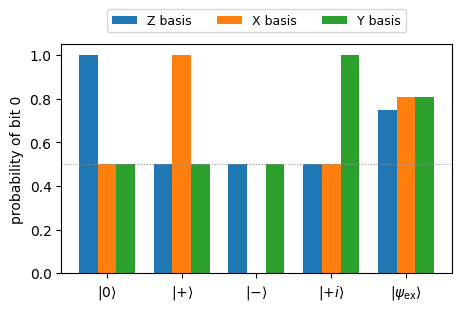

In [15]:
BASIS_CHANGE = {"Z": I2, "X": H, "Y": H @ S.conj().T}       # apply this unitary, then measure Z

def probabilities_in_basis(psi, basis):
    return born_probabilities(BASIS_CHANGE[basis] @ psi)

states = {"|0>": ket0, "|+>": plus, "|->": minus, "|+i>": normalise(ket0 + 1j*ket1), "psi_ex": psi_ex}
table = {}
print(f"{'state':8s}  p(0) in Z     X      Y")
for name, s in states.items():
    row = [float(probabilities_in_basis(s, b)[0]) for b in "ZXY"]
    table[name] = row
    print(f"{name:8s}  {row[0]:.3f}     {row[1]:.3f}  {row[2]:.3f}")
    for b, P in zip("ZXY", (Z, X, Y)):
        assert abs(probabilities_in_basis(s, b)[0] - (1 + expectation(P, s)) / 2) < TOL

fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
width = 0.25
xs = np.arange(len(states))
for k, b in enumerate("ZXY"):
    ax.bar(xs + (k - 1) * width, [table[n][k] for n in states], width, label=f"{b} basis")
tick_labels = {"|0>": r"$|0\rangle$", "|+>": r"$|{+}\rangle$", "|->": r"$|{-}\rangle$", "|+i>": r"$|{+i}\rangle$", "psi_ex": r"$|\psi_{\rm ex}\rangle$"}
ax.set_xticks(xs, [tick_labels[s_] for s_ in states], fontsize=10)
ax.set_ylabel("probability of bit 0")
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color="0.6", lw=0.8, ls=":")
ax.legend(fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
save(fig, "fig_lab064_bases"); plt.show()
NUMBERS.update(PzeroXEx=table["psi_ex"][1], PzeroYEx=table["psi_ex"][2])

The bars show the probability of the bit 0 in each basis. A bar at 1 or 0 marks a certain outcome, and a bar at 0.5 (dotted line) a fair coin. No state has certain outcomes in two bases at once. The pair $|{+}\rangle$, $|{-}\rangle$ is indistinguishable in the $\hat Z$ basis and distinguishable with certainty in the $\hat X$ basis. The example state leans towards the bit 0 in all three bases, $p(0)=0.75$, $0.81$ and $0.81$. Its Bloch vector points into the octant with positive $x$, $y$ and $z$.

## 11. Shots and the estimate of an expectation value

An experiment repeats preparation and measurement $M$ times. Each repetition is a *shot* and returns a value $z_j=\pm1$, and we estimate $\langle \hat Z\rangle$ by the sample mean,
$$\bar z=\frac1M\sum_{j=1}^M z_j . \tag{28}$$
Its average over many records is $\langle \hat Z\rangle$, so the estimator is unbiased. A single outcome has the variance $\langle \hat Z^2\rangle-\langle \hat Z\rangle^2=1-\langle \hat Z\rangle^2$, because $z_j^2=1$, and the shots are independent, so the standard error of the mean is
$$\mathrm{std}(\bar z)=\sqrt{\frac{1-\langle \hat Z\rangle^2}{M}} . \tag{29}$$
Doubling the precision costs four times as many shots. In practice $\langle \hat Z\rangle$ is unknown, and we estimate the standard error from the sample standard deviation of the record divided by $\sqrt M$.

We simulate the records with explicit `jax.random` keys, so every number is reproducible. A shot draws a uniform number $u\in[0,1)$ and returns the bit 1 when $u<p(1)$. For several record lengths $M$ we repeat the whole experiment $R=400$ times and compare the observed spread of the estimates with equation (29).

one record of 1000 shots: <Z> estimate 0.4840 +- 0.0277   (exact 0.4999999999999999)
first 30 bits: 010100001110000010000110101001
M =     10: observed spread 0.2588, formula 0.2739
M =     30: observed spread 0.1572, formula 0.1581
M =    100: observed spread 0.0894, formula 0.0866
M =    300: observed spread 0.0498, formula 0.0500
M =   1000: observed spread 0.0287, formula 0.0274
M =   3000: observed spread 0.0170, formula 0.0158
M =  10000: observed spread 0.0090, formula 0.0087


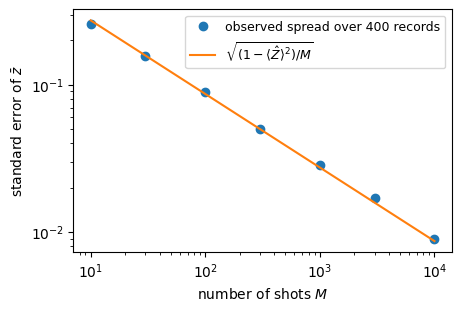

In [16]:
def sample_bits(key, p1, shots):
    # shots independent measurements; bit 1 with probability p1
    return (jax.random.uniform(key, (shots,)) < p1).astype(jnp.int32)

key = jax.random.PRNGKey(64)
p1_ex = float(p_ex[1])
z_true = float(ez)

# one record of 1000 shots, analysed like a laboratory record
key, sub = jax.random.split(key)
bits = sample_bits(sub, p1_ex, 1000)
z = 1 - 2 * bits                                          # bit 0 -> +1, bit 1 -> -1
z_hat, se_hat = float(z.mean()), float(z.std(ddof=1) / jnp.sqrt(1000))
print(f"one record of 1000 shots: <Z> estimate {z_hat:.4f} +- {se_hat:.4f}   (exact {z_true})")
print("first 30 bits:", "".join(map(str, np.asarray(bits[:30]))))

# spread of the estimate over R independent records, for several record lengths
R = 400
Ms = np.array([10, 30, 100, 300, 1000, 3000, 10000])
spread = []
for M_ in Ms:
    key, sub = jax.random.split(key)
    recs = (jax.random.uniform(sub, (R, int(M_))) < p1_ex).astype(jnp.float64)
    est = (1 - 2 * recs).mean(axis=1)
    spread.append(float(est.std(ddof=1)))
spread = np.array(spread)
theory = np.sqrt((1 - z_true**2) / Ms)
for M_, s_, t_ in zip(Ms, spread, theory):
    print(f"M = {M_:6d}: observed spread {s_:.4f}, formula {t_:.4f}")
assert np.all(np.abs(spread / theory - 1) < 0.15)          # agreement within the sampling error of R = 400 records

fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ax.loglog(Ms, spread, "o", label="observed spread over 400 records")
ax.loglog(Ms, theory, "-", label=r"$\sqrt{(1-\langle\hat Z\rangle^2)/M}$")
ax.set_xlabel("number of shots $M$")
ax.set_ylabel(r"standard error of $\bar z$")
ax.legend(fontsize=9)
save(fig, "fig_lab064_shots"); plt.show()
NUMBERS.update(ZhatThousand=z_hat, SEhatThousand=se_hat, SEtheoryThousand=float(np.sqrt((1 - z_true**2) / 1000)))

The points lie on a straight line of slope $-1/2$ in the double-logarithmic plot, the $1/\sqrt M$ law of equation (29). With 1000 shots the estimate of $\langle \hat Z\rangle=0.5$ carries an error of about $0.027$, and each further decimal digit of precision needs one hundred times more shots. Every expectation value measured on a quantum device has this statistical error, and variational quantum algorithms have to budget it. The Ramsey experiment of Section 9 is repeated next with 200 shots for each phase.

largest deviation from the formula in standard errors: 1.9476405637870378


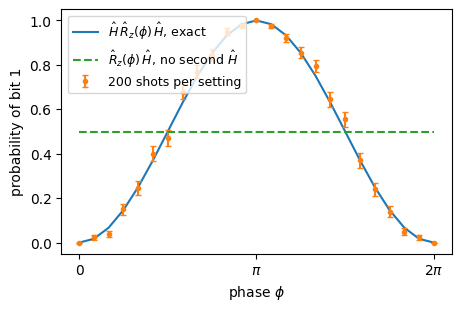

In [17]:
shots = 200
est, err, p1_exact = [], [], []
for phi in phis:
    p_w = float(born_probabilities(H @ Rz(phi) @ H @ ket0)[1])
    key, sub = jax.random.split(key)
    b = sample_bits(sub, p_w, shots)
    m = float(b.mean())
    p1_exact.append(p_w); est.append(m); err.append(np.sqrt(m * (1 - m) / shots))

fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
ax.plot(phis, p1_exact, "-", label=r"$\hat H\,\hat R_z(\phi)\,\hat H$, exact")
ax.errorbar(phis, est, yerr=err, fmt="o", ms=3, capsize=2, label="200 shots per setting")
ax.plot(phis, p1_without, "--", label=r"$\hat R_z(\phi)\,\hat H$, no second $\hat H$")
ax.set_xlabel(r"phase $\phi$"); ax.set_ylabel("probability of bit 1")
ax.set_xticks([0, np.pi, 2 * np.pi], ["0", r"$\pi$", r"$2\pi$"])
ax.legend(fontsize=9, loc="upper left")
save(fig, "fig_lab064_ramsey"); plt.show()
chi = np.abs(np.array(est) - np.array(p1_exact)) / np.maximum(np.array(err), 1e-9)
print("largest deviation from the formula in standard errors:", float(np.max(chi[np.array(err) > 0])))

The measured points follow equation (26) within about two error bars $\sqrt{p(1-p)/200}$, and the largest deviation printed above stays below two standard errors. The bars use the estimated $p$, so they vanish where every shot gave the same bit. Near $\phi=0$ and $2\pi$ the outcome is almost certain and the bars are short, and near $p=1/2$ they are longest. Such a record is what an experiment delivers. The core route of Sections 0 to 11 ends here.

## 12. The Euler decomposition

Beyond the core route, any $2\times2$ unitary can be written as
$$\hat U=e^{i\eta}\hat R_z(\theta_1)\,\hat R_y(\theta_2)\,\hat R_z(\theta_3), \tag{30}$$
the *Euler decomposition* with three angles $\theta_1,\theta_2,\theta_3$ and a global phase $\eta$. A product of rotations is again a rotation, so the single-qubit gates are the rotations of the Bloch sphere, up to a global phase. The code finds the Euler angles of the Hadamard gate and of a random unitary from the matrix elements and rebuilds the matrices. For a diagonal gate such as $\hat T$ the angle $\theta_2$ vanishes and only the sum $\theta_1+\theta_3$ is determined.

In [19]:
def euler_zyz(U):
    # U = e^{i eta} Rz(th1) Ry(th2) Rz(th3), read from the matrix elements of the phase-free W
    eta = jnp.angle(jnp.linalg.det(U)) / 2
    W = U * jnp.exp(-1j * eta)
    th2 = 2 * jnp.arctan2(jnp.abs(W[1, 0]), jnp.abs(W[0, 0]))
    s = jnp.angle(W[1, 1]) * 2          # th1 + th3
    d = jnp.angle(W[1, 0]) * 2          # th1 - th3
    th1, th3 = (s + d) / 2, (s - d) / 2
    return float(eta), float(th1), float(th2), float(th3)

def rebuild(eta, th1, th2, th3):
    return jnp.exp(1j * eta) * Rz(th1) @ Ry(th2) @ Rz(th3)

angles_H = euler_zyz(H)
print("Hadamard: eta, theta_1, theta_2, theta_3 / pi =", np.round(np.array(angles_H) / np.pi, 4))
assert jnp.allclose(rebuild(*angles_H), H, atol=1e-10)
angles_T = euler_zyz(T)
print("T gate:   eta, theta_1, theta_2, theta_3 / pi =", np.round(np.array(angles_T) / np.pi, 4))
assert jnp.allclose(rebuild(*angles_T), T, atol=1e-10)
sub = jax.random.PRNGKey(640)                    # own key for this optional cell
A = jax.random.normal(sub, (2, 2)) + 1j * jax.random.normal(jax.random.split(sub)[0], (2, 2))
U_rand, _ = jnp.linalg.qr(A)                    # a random unitary
assert jnp.allclose(rebuild(*euler_zyz(U_rand)), U_rand, atol=1e-10)
print("random unitary rebuilt from its Euler angles")

Hadamard: eta, theta_1, theta_2, theta_3 / pi = [0.5 0.  0.5 1. ]
T gate:   eta, theta_1, theta_2, theta_3 / pi = [0.125 0.125 0.    0.125]
random unitary rebuilt from its Euler angles


## 13. Exercises

1. Compute the probabilities of the bit 0 for the example state in the $\hat X$ and $\hat Y$ bases from its Bloch vector. Compare them with the table of Section 10.
2. Show from the length of the Bloch vector that no pure state of one qubit gives a fair coin in all three bases.
3. Find the number of shots needed to estimate $\langle \hat Z\rangle=0.5$ with a standard error of $0.001$.
4. Show with equation (22) that $\hat R_x(\pi/2)$ takes $|0\rangle$ to a point on the equator, and find its azimuth.
5. Decompose $\hat T$ with `euler_zyz`. Show that $\theta_2=0$ and that for a diagonal gate only the sum $\theta_1+\theta_3$ is fixed, so the decomposition is not unique. The code returns $\eta=\theta_1=\theta_3=\pi/8$ and $\theta_2=0$.

## 14. Summary

We described one qubit by two complex amplitudes and predicted its measurement records with the Born rule in three bases. Every evolution, and with it every single-qubit gate, is a rotation of the Bloch sphere generated by a Hamiltonian switched on for a chosen time. Interference turns a relative phase into a population, and measurements in other bases are rotations followed by a $\hat Z$ measurement. Expectation values estimated from $M$ shots carry the statistical error $1/\sqrt M$. A second qubit adds the tensor product, bit strings of several qubits, two-qubit gates and entanglement.